# Specific Rock


<b> Objective: </b>
Test the "start small with one rock type, then expand" suggestion: does a model trained on one rock
class beat the model trained on everything?

----------------------

<i><b>Author: </b> Salvador Palma <br>
<b>Institution: </b> Copenhagen University </i>

Whole rock only (stream sediment has no rock type). Same data, targets, folds and model as
notebook 2.

### Imports

In [13]:
import sys
import os
COLAB_SESSION = False

DRIVE_PATH = ""
if COLAB_SESSION:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=True)
    DRIVE_PATH = "/content/drive/MyDrive/UCPH/POOCS/"
    sys.path.insert(0, DRIVE_PATH)

import re
import json
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.ensemble import HistGradientBoostingRegressor

pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 200)

### Setup

In [14]:
DATA_PATH = "Data/Whole Rock/Mean Merge/"
RESULTS_PATH = "Results/Whole Rock/Mean Merge/"

df = pd.read_csv(f"{DRIVE_PATH}{DATA_PATH}Data.csv", delimiter=";", low_memory=False)
with open(f"{DRIVE_PATH}Data/whole-rock.json") as f:
    schema = json.load(f)

elementCols = [c for c in df.columns if c not in schema["metaCols"] + schema["physicalCols"]]
coverage = df[elementCols].notna().sum()
elementCols = [c for c in elementCols if coverage[c] >= 10]
targets = [c for c in elementCols if coverage[c] >= 1000]

with open(f"{DRIVE_PATH}{DATA_PATH}5-Fold.kfold") as f:
    kfold = json.load(f)
folds = [(pd.Index(kfold[k]["train"]), pd.Index(kfold[k]["test"])) for k in sorted(kfold, key=int)]

print(f"Samples: {len(df)}   Targets: {len(targets)}   Folds: {len(folds)}")

Samples: 6957   Targets: 48   Folds: 5


### Rock Classes

`Rock description` is built from a small vocabulary, e.g. *"high-grade metamorphic medium-grained
mafic magmatic plutonic rock"*. Each attribute is parsed into its own column. Order matters where
one word contains another (`ultramafic` before `mafic`, `volcanic-sedimentary` before
`sedimentary`).

In [15]:
ATTRIBUTES = {
    "composition": ["ultramafic", "mafic", "intermediate", "felsic"],
    "grade":       ["high-grade metamorphic", "low-grade metamorphic"],
    "grain":       ["fine-grained", "medium-grained", "coarse-grained"],
    "origin":      ["volcanic-sedimentary", "sedimentary", "magmatic"],
    "setting":     ["plutonic", "hypabyssal", "extrusive", "volcanic"],
}


def ParseClass(description, classes: list[str]) -> str:
    if not isinstance(description, str):
        return None
    description = description.lower()
    for name in classes:
        if re.search(r"(?<![a-z-])" + re.escape(name) + r"(?![a-z])", description):
            return name
    return None


for attribute, classes in ATTRIBUTES.items():
    df[attribute] = df["Rock description"].map(lambda d, c=classes: ParseClass(d, c))

classCounts = pd.DataFrame([
    { "attribute": attribute, "class": name, "n": int((df[attribute] == name).sum()) }
    for attribute, classes in ATTRIBUTES.items() for name in classes
])
classCounts["unlabelled"] = classCounts["attribute"].map(lambda a: int(df[a].isna().sum()))

print(f"Samples with any description: {df['Rock description'].notna().sum()}")
display(classCounts.set_index(["attribute", "class"]))

Samples with any description: 4120


n  unlabelled
attribute   class                                   
composition ultramafic               308        3734
            mafic                   1231        3734
            intermediate             505        3734
            felsic                  1179        3734
grade       high-grade metamorphic  2717        3880
            low-grade metamorphic    360        3880
grain       fine-grained             882        3867
            medium-grained          2031        3867
            coarse-grained           177        3867
origin      volcanic-sedimentary     406        3760
            sedimentary              331        3760
            magmatic                2460        3760
setting     plutonic                1178        4307
            hypabyssal               674        4307
            extrusive                396        4307
            volcanic                 402        4307

### Combining Classes

Classes from different attributes are intersected to get closer to specific rock types, e.g.
`felsic + plutonic` ≈ granite. Every combination of up to `MAX_ATTRIBUTES` attributes with at least
`MIN_GROUP` samples becomes a test group. Groups with identical members are merged under their
shortest name (every `plutonic` sample is also `magmatic`, so `magmatic + plutonic` is dropped).

`MIN_GROUP` keeps the local model above ~50 training samples per fold for most elements.

In [16]:
MAX_ATTRIBUTES = 3
MIN_GROUP = 250


def BuildGroups(maxAttributes: int = MAX_ATTRIBUTES, minGroup: int = MIN_GROUP) -> pd.DataFrame:
    rows, seen = [], {}
    for size in range(1, maxAttributes + 1):
        for attributes in itertools.combinations(ATTRIBUTES, size):
            counts = df[list(attributes)].dropna().value_counts()
            for classes, n in counts.items():
                if n < minGroup:
                    continue
                mask = np.logical_and.reduce([df[a] == c for a, c in zip(attributes, classes)])
                members = frozenset(df.index[mask])
                #Identical membership under a longer name adds nothing
                if members in seen:
                    continue
                seen[members] = True
                rows.append({ "group": " + ".join(classes), "attributes": size,
                              "n": int(n), "members": pd.Index(sorted(members)) })
    return pd.DataFrame(rows).sort_values(["attributes", "n"], ascending=[True, False]).reset_index(drop=True)


groups = BuildGroups()
print(f"{len(groups)} groups: " + ", ".join(f"{(groups.attributes == s).sum()} with {s} attribute(s)" for s in range(1, MAX_ATTRIBUTES + 1)))
display(groups[["group", "attributes", "n"]])

66 groups: 15 with 1 attribute(s), 33 with 2 attribute(s), 18 with 3 attribute(s)


,group,attributes,n
0,high-grade metamorphic,1,2717
1,magmatic,1,2460
2,medium-grained,1,2031
3,mafic,1,1231
4,felsic,1,1179
5,plutonic,1,1178
6,fine-grained,1,882
7,hypabyssal,1,674
8,intermediate,1,505
9,volcanic-sedimentary,1,406


### Variance Explained by Rock Class

η² per element: the share of its variance explained by an attribute alone. High means the element
mostly *is* that rock distinction; low means it varies independently of it.

In [17]:
def EtaSquared(element: str, attribute: str) -> float:
    s = df[[element, attribute]].dropna()
    if len(s) < 100:
        return np.nan
    grand = s[element].mean()
    total = ((s[element] - grand) ** 2).sum()
    between = s.groupby(attribute)[element].apply(lambda x: len(x) * (x.mean() - grand) ** 2).sum()
    return between / total if total > 0 else np.nan


eta = pd.DataFrame({ a: { t: EtaSquared(t, a) for t in targets } for a in ATTRIBUTES })
display(eta.agg(["median", "mean", "max"]).round(3))
print("Highest for composition:", ", ".join(f"{e} {v:.2f}" for e, v in eta["composition"].nlargest(6).items()))

,composition,grade,grain,origin,setting
median,0.060,0.002,0.005,0.012,0.060
mean,0.118,0.004,0.006,0.022,0.068
max,0.546,0.023,0.039,0.093,0.326


Highest for composition: FeO wt% 0.55, MgO wt% 0.46, Cr ppm 0.39, Ni ppm 0.37, MnO wt% 0.37, Fe2O3 wt% 0.33


### Training

Per target and fold, all scored on the same held-out samples:

| model | trained on |
|---|---|
| `pooled` | every training sample |
| `pooled+rock` | the same, plus every attribute one-hot encoded |
| `local` | training samples of the group only |
| `sized` | a random draw from all training samples, same size as `local` |

`sized` separates specificity from data size. The scores are cached; delete the file to retrain.

In [18]:
CACHE_FILE = f"{DRIVE_PATH}{RESULTS_PATH}E1_SpecificRock_Scores.csv"
MIN_TRAIN = 50
MIN_SCORED = 40

rockCols = list(pd.get_dummies(df[list(ATTRIBUTES)], dtype=float).columns)
dfX = pd.concat([df, pd.get_dummies(df[list(ATTRIBUTES)], dtype=float)], axis=1)


def FitPredict(trainIdx: pd.Index, testIdx: pd.Index, target: str, featureCols: list[str]) -> pd.Series:
    train = dfX.loc[trainIdx].dropna(subset=[target])
    usable = [c for c in featureCols if c != target and train[c].nunique(dropna=True) >= 2]
    test = dfX.loc[testIdx].dropna(subset=[target])
    if len(train) < MIN_TRAIN or test.empty or not usable:
        return pd.Series(dtype=float)
    model = HistGradientBoostingRegressor(max_iter=200, random_state=42).fit(train[usable], train[target])
    return pd.Series(model.predict(test[usable]), index=test.index)


def TrainJob(target: str, foldIdx: int) -> dict:
    trainIdx, testIdx = folds[foldIdx]
    out = { "pooled": FitPredict(trainIdx, testIdx, target, elementCols),
            "pooled+rock": FitPredict(trainIdx, testIdx, target, elementCols + rockCols) }

    rng = np.random.default_rng(1000 + foldIdx)
    measured = trainIdx[df.loc[trainIdx, target].notna().to_numpy()]
    for row in groups.itertuples():
        groupTrain = measured.intersection(row.members)
        groupTest = testIdx.intersection(row.members)
        if len(groupTrain) < MIN_TRAIN or groupTest.empty:
            continue
        out[f"local|{row.group}"] = FitPredict(groupTrain, groupTest, target, elementCols)
        sized = pd.Index(rng.choice(measured, size=len(groupTrain), replace=False))
        out[f"sized|{row.group}"] = FitPredict(sized, groupTest, target, elementCols)
    return out


def Score(predictions: pd.Series, target: str) -> dict:
    if len(predictions) < MIN_SCORED:
        return None
    truth = df.loc[predictions.index, target].to_numpy()
    guess = predictions.to_numpy()
    total = ((truth - truth.mean()) ** 2).sum()
    return { "r2": 1 - ((truth - guess) ** 2).sum() / total if total > 0 else np.nan,
             "mae": float(np.abs(truth - guess).mean()), "n": len(predictions) }


def RunAndScore() -> pd.DataFrame:
    jobs = [(t, f) for t in targets for f in range(len(folds))]
    outputs = Parallel(n_jobs=-1)(delayed(TrainJob)(t, f) for t, f in jobs)

    #Out-of-fold predictions pooled across folds, so each test sample is scored once
    predictions = {}
    for (target, _), out in zip(jobs, outputs):
        for name, series in out.items():
            predictions.setdefault((target, name), []).append(series)
    predictions = { key: pd.concat(parts) for key, parts in predictions.items() }

    rows = []
    for target in targets:
        for scope, members in [("all", None)] + list(zip(groups["group"], groups["members"])):
            names = ["pooled", "pooled+rock"] + ([] if members is None else [f"local|{scope}", f"sized|{scope}"])
            for name in names:
                p = predictions.get((target, name))
                if p is None:
                    continue
                if members is not None:
                    p = p[p.index.isin(members)]
                s = Score(p, target)
                if s:
                    rows.append({ "scope": scope, "target": target, "model": name.split("|")[0], **s })
    return pd.DataFrame(rows)


if os.path.exists(CACHE_FILE):
    scores = pd.read_csv(CACHE_FILE, delimiter=";")
    print(f"Loaded {len(scores)} cached scores")
else:
    scores = RunAndScore()
    scores.to_csv(CACHE_FILE, sep=";", index=False)
    print(f"Trained and cached {len(scores)} scores")

Loaded 12444 cached scores


### Results per Group

Each row is one group; every value is the mean over the targets scored on **that group's test samples**:

| column | meaning |
|---|---|
| `pooled` | model trained on all samples (chemistry only), scored on this group |
| `local` | model trained only on this group's samples |
| `sized` | model trained on a random draw from all samples, same size as `local`'s training set |
| `pooled_rock` | `pooled` plus the rock classes one-hot encoded |
| `local_beats_pooled` / `local_beats_sized` | share of targets where `local` scores higher |

`local` vs `pooled` answers "should we start small?"; `local` vs `sized` isolates the effect of
specificity from the effect of having less data. MAE is included because R² inside a group is
mechanically lower (less variance to explain).

In [21]:
def GroupTable() -> pd.DataFrame:
    wide = scores.pivot_table(index=["scope", "target"], columns="model", values=["r2", "mae"])
    wide.columns = [f"{model}_{metric}" for metric, model in wide.columns]
    wide = wide.dropna(subset=["local_r2", "sized_r2", "pooled_r2"]).reset_index()

    table = wide.groupby("scope").agg(
        targets=("target", "size"),
        pooled=("pooled_r2", "mean"), local=("local_r2", "mean"), sized=("sized_r2", "mean"),
        pooled_rock=("pooled+rock_r2", "mean"),
        pooled_mae=("pooled_mae", "mean"), local_mae=("local_mae", "mean"),
    )
    table["local_beats_pooled"] = wide.assign(w=wide.local_r2 > wide.pooled_r2).groupby("scope")["w"].mean()
    table["local_beats_sized"] = wide.assign(w=wide.local_r2 > wide.sized_r2).groupby("scope")["w"].mean()
    return (groups.set_index("group")[["attributes", "n"]].join(table, how="inner")
            .sort_values(["attributes", "n"], ascending=[True, False]))


groupTable = GroupTable()
overall = scores[(scores.scope == "all")].groupby("model")["r2"].mean()

print(f"Pooled, all samples: R2 {overall['pooled']:.4f}   |   pooled+rock: {overall['pooled+rock']:.4f}")
print(f"Pooled within groups: mean R2 {groupTable.pooled.mean():.4f} (range {groupTable.pooled.min():.3f}-{groupTable.pooled.max():.3f})")
print(f"Local beats pooled on {groupTable.local_beats_pooled.mean():.0%} of group-element pairs; "
      f"beats size-matched on {groupTable.local_beats_sized.mean():.0%}")
print(f"Groups where local wins on average: {(groupTable.local > groupTable.pooled).sum()}/{len(groupTable)}")
display(groupTable.round(3))

Pooled, all samples: R2 0.7987   |   pooled+rock: 0.8004
Pooled within groups: mean R2 0.7484 (range 0.643-0.811)
Local beats pooled on 4% of group-element pairs; beats size-matched on 93%
Groups where local wins on average: 0/66


,attributes,n,targets,pooled,local,sized,pooled_rock,pooled_mae,local_mae,local_beats_pooled,local_beats_sized
high-grade metamorphic,1,2717,48,0.767,0.761,0.715,0.769,0.167,0.169,0.375,0.979
magmatic,1,2460,48,0.804,0.795,0.755,0.806,0.156,0.160,0.188,0.979
medium-grained,1,2031,48,0.792,0.769,0.721,0.794,0.156,0.163,0.062,0.979
mafic,1,1231,48,0.761,0.714,0.629,0.762,0.158,0.170,0.062,1.000
felsic,1,1179,48,0.759,0.717,0.653,0.762,0.162,0.175,0.083,0.917
plutonic,1,1178,48,0.794,0.757,0.700,0.796,0.154,0.166,0.062,0.958
fine-grained,1,882,48,0.780,0.717,0.664,0.783,0.162,0.183,0.021,0.938
hypabyssal,1,674,48,0.811,0.760,0.639,0.813,0.158,0.178,0.000,0.979
intermediate,1,505,47,0.756,0.643,0.533,0.759,0.167,0.199,0.021,0.830
volcanic-sedimentary,1,406,45,0.740,0.663,0.486,0.742,0.174,0.199,0.022,1.000


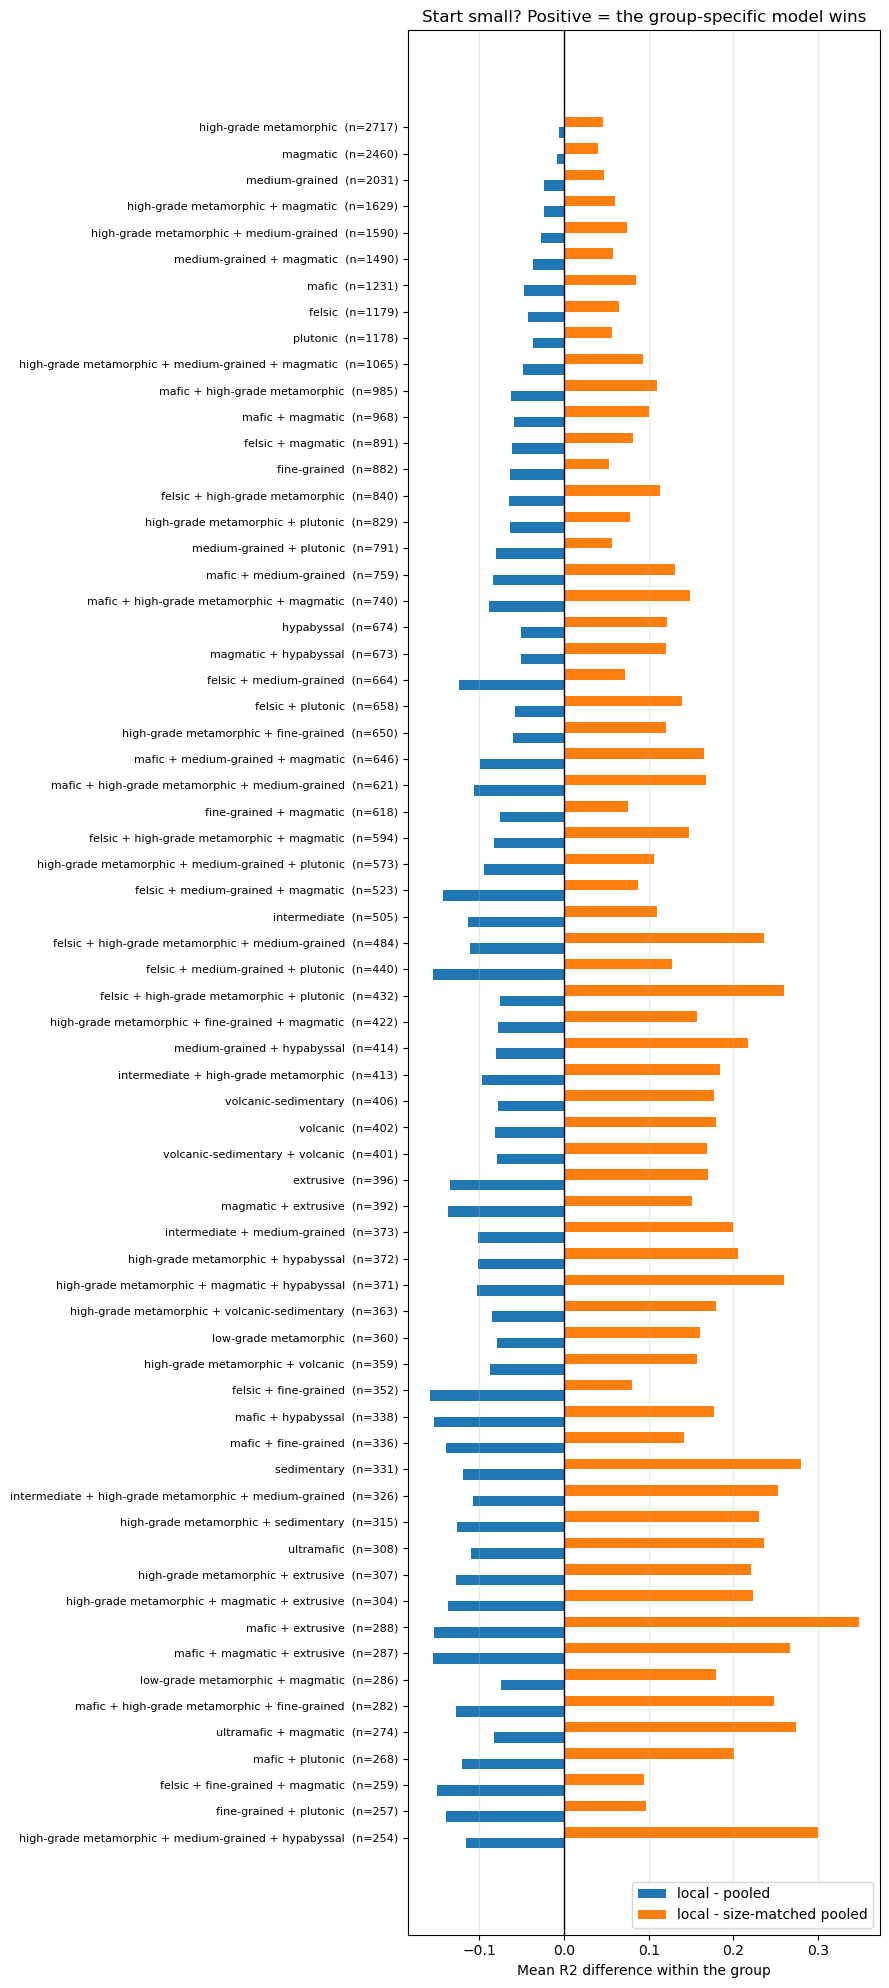

In [20]:
def DisplayGroups(table: pd.DataFrame):
    table = table.sort_values("n")
    y = np.arange(len(table))
    fig, ax = plt.subplots(figsize=(9, 0.28 * len(table) + 1.5))
    ax.barh(y - 0.2, table.local - table.pooled, 0.4, label="local - pooled")
    ax.barh(y + 0.2, table.local - table.sized, 0.4, label="local - size-matched pooled")
    ax.axvline(0, color="black", linewidth=1)
    ax.set_yticks(y, [f"{g}  (n={n})" for g, n in zip(table.index, table.n)], fontsize=8)
    ax.set_xlabel("Mean R2 difference within the group")
    ax.set_title("Start small? Positive = the group-specific model wins")
    ax.grid(alpha=0.3, axis="x")
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()


DisplayGroups(groupTable)

### Reading the Results

Against the cached run (66 groups, 48 targets):

* **Start small loses everywhere.** The local model wins on average in **0 of 66 groups**, and on only 4% of group–element pairs.
* **Granite** (`felsic + plutonic`, 658 samples): pooled 0.764, local 0.706, size-matched 0.567.
* **Narrower is worse.** Mean local − pooled is −0.066 for single classes, −0.090 for two combined and −0.110 for three. The groups closest to winning are the broadest ones, which are nearly the whole dataset.
* **Specificity is real but small.** At equal size, local beats pooled on 93% of pairs, so element relationships do differ by rock type. The extra data from other rocks outweighs it.
* **The baseline is not a rock-type artefact.** Pooled R² within groups averages 0.748 against 0.799 overall. Composition explains a median 6% of an element's variance; the other attributes under 1%.
* **Rock type as a feature adds nothing** (0.7987 → 0.8004): the chemistry already encodes it.

Limits: classes come from the sampler's text (59% of samples described), not a curated rock type; random CV.